# Quantum Metal tutorial 1.3 — four TransmonPockets in a ring of meandered buses (Quantcore PDK rebuild)

**What the chip is.** The Qiskit Metal tutorial `docs/tut/1-Overview/1.3-Build-a-4-qubit-chip.ipynb` (© IBM and Qiskit
Metal contributors, Apache-2.0, <https://github.com/qiskit-community/qiskit-metal>); spec
`docs/designs/metal/tut13_four_qubit_ring.md`. We distribute the rebuild under GPL-3.0. Four `TransmonPocket`s
(Q1 / Q3 at (±2.55, 0) mm, Q2 / Q4 at (0, ∓0.9) mm rotated 90°), each with four connection pads `a`–`d`, joined in a
ring by four `RouteMeander` buses (6.0 / 6.1 / 6.0 / 6.1 mm, ±150 µm asymmetry, fillet 90 µm). No readout,
launchpads or control lines: this is the core that tutorial 2.21 / circuit example 51 extend into a full chip.

**This notebook rebuilds it with our library and the Quantcore PDK** (PDK v3, `quantcore_nb_sapphire_v1`): the
Metal components are drawn through the `metal:<Class>` wrapper with the tutorial's own options; the chip, the stack,
the junctions, the routes, the netlist and the LOM are ours.

| | Qiskit Metal tutorial 1.3 | Quantcore PDK rebuild |
|---|---|---|
| chip | `DesignPlanar` default 9 × 6 mm centred on (0, 0) | the 7.5 × 7.5 mm Quantcore die with the QCT frame; the ring (≈ 6 × 2.7 mm) fits, so the die is centred on Metal's chip centre (`box=(750, −750, 8250, 6750)`) and every coordinate stays the source's (+4.5, +3) mm |
| substrate | silicon 750 µm, εr 11.45 (Metal default) | sapphire 650 µm, εr 10.25 (LOM and FEM) |
| pads | none | none (nothing for the pad rule to move) |
| junctions | `FakeJunction_01`, no inductance stated | Quantcore Nb/AlOx/Nb trilayer junction, PDK nominal 0.5 × 0.6 µm (R_n 45 kΩ, L_J 6.73 nH, C_J 15 fF) |
| cheese | none (the tutorial never exports a GDS) | the PDK band (chip `cheese: "auto"`) |
| buses | `RouteMeander` 6.0 / 6.1 mm | qcc fixed-length routes on Metal's own meander corner points, the same lengths |
| placement | as drawn | content centred in the die (already centred) |

**Kept exactly:** the qubits with the tutorial's options (`pad_width` 425 µm, `pocket_height` 650 µm, the four
connection pads with pad `b` 30 µm and `d` 50 µm high and pad `c` 200 µm wide), positions and orientations, every
bus's end pins and total length, and the meanders themselves: Metal's `RouteMeander` corner points (130 µm lead,
200 µm run pitch, 100 µm meander leads) are the waypoints, with Metal's 90 µm fillet, so the lengths are Metal's. The
10/6 µm CPW state (the tutorial's later variables cell, 25/12 µm and `pad_width` 450 µm, is a variant not built
here).

**How this notebook goes.** First the **Design**: the chip is laid out one segment at a time, each segment its own cell with a
picture of the chip so far — the die, the four qubits, the ring of buses, and then the whole chip (no pads, readouts
or control lines: those segments say so in one sentence). Then the same steps as the Flow strip of the Quantcore
KLayout plugin: **Check** (DRC, netlist) → **LOM** (simulation and plots) → **Simulate** (export to HFSS, the
component simulation, the eigenmode simulation, the full-wave run) → **Results** (plots, the values, FEM against the
LOM, a feedback step and the iteration to a target) → **Fab**.

**Nothing here solves on its own.** The switches (the code cell after Setup) are off (`RUN_FEM = False`): FEM results
are loaded when a solve has been kept, otherwise each FEM cell says what would appear. The notebook before this
rewrite (the layout in one cell, with its outputs) is kept as `tut13_four_qubit_ring.v1.ipynb`; both save the same
`tut13_four_qubit_ring.json`.

## Setup

The imports, the output folder, the Metal → Designer helper `P`, Metal's meander geometry (`RUNS`, `bus()`) and the switches. `LIVE`: with KLayout open (the default) every change below is pushed to the KLayout window as you run it;
with `QCC_LIVE=0` the notebook builds headless and only writes files. `_common` holds the helpers the design
notebooks share (tables, snapshots, the PDK placement, the FEM and feedback steps).

**The switches** (next cell): `RUN_FEM` solves the FEM jobs in AEDT 2024 R1 or newer, one after the other (a new
non-graphical AEDT unless `AEDT_MODE` says otherwise; an AEDT you have open is never touched); `RESOLVE` solves again
even when kept results match; `FEM_FAST` exports with the library's fast test settings (minutes, values not
converged); `MAX_ITER` caps the feedback iterations towards the targets.

In [2]:
%config InlineBackend.figure_formats = ["png"]
import math, os, sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
os.chdir(ROOT)                                   # paths below are relative to the repo root
sys.path.insert(0, str(ROOT / "examples" / "designs"))
from _common import *                            # tables, snapshots, PDK placement, FEM and feedback helpers
from quantcore_circuits.designer import Designer
from quantcore_circuits.layouts.registry import trilayer_junction
from quantcore_circuits.lom.simulate import simulate
from quantcore_circuits.pdk import get_pdk

LIVE = os.environ.get("QCC_LIVE", "1") == "1"   # live KLayout by default; QCC_LIVE=0 for batch runs
OUT = Path("examples/designs/metal")             # this notebook's design JSON and PNG snapshots
X0, Y0 = 4500, 3000                              # Metal's default 9 × 6 mm chip is centred on (0, 0)
P = lambda x, y: (X0 + x, Y0 + y)                # Metal µm → Designer µm
R = 90                                           # Metal fillet
EPS = 0.05                                       # the waypoint path is Metal's length to < 0.05 µm: the fixed-length
                                                 # (λ/2 bus) route needs a target at or above it
RUNS = [1795, 1595, 1395, 1195, 995, 795, 595, 395]  # Metal's meander run positions (|x|, µm)


def bus(far, near, sx, sy):
    """Interior corner points of Metal's RouteMeander from a Q1/Q3 pad (|x| = 2125, |y| = 195) to a Q2/Q4 pad
    (|x| = 195, |y| = 475): runs alternating between |y| = far and near, mirrored by the signs (sx, sy)."""
    pts = [(1795, 195)]
    for k, x in enumerate(RUNS):
        y = far if k % 2 == 0 else near
        if k:
            pts.append((x, pts[-1][1]))
        pts.append((x, y))
    pts.append((195, pts[-1][1]))
    return [P(sx * x, sy * y) for x, y in pts]

In [3]:
RUN_FEM = False        # True (or a set such as {"q3d_cmatrix"}): solve the FEM jobs in AEDT 2024 R1+, one at a time
RESOLVE = False        # True (or a set of analyses): solve again even when kept results match
FEM_FAST = True        # True: the library's fast test settings (minutes, not converged); False: the settings as written
AEDT_MODE = "batch"    # "batch" (no window) | "gui" (a new AEDT window, left open) | "attach" (the AEDT you have open)
MAX_ITER = 3           # feedback iterations towards the targets (Results 5)

## The Quantcore PDK this chip uses

The rebuild takes every process fact from the PDK (`get_pdk()`), not from the source: the stack the LOM and the FEM
jobs use, the die frame, where pads go, which junction is drawn, the cheese and the 3/0 keep-outs. For this chip that means: the 7.5 mm die gets the QCT frame; there are no pads for the pad rule; the four qubits get the PDK nominal trilayer junction; the free ground gets the PDK cheese band.

In [4]:
display(Markdown(pdk_facts_md()))

| PDK rule | value |
|---|---|
| process | `quantcore_nb_sapphire_v1` v3 |
| stack | sapphire 650 µm, εr 10.25, Nb film (λ_L 0.09 µm) |
| CPW default | centre 10 µm, gap 6 µm, bend radius 100 µm |
| die frame | standard die 7.5 × 7.5 mm; L dicing markers (1000/0, 25 µm wide), 3 × 3 alignment grids (1001/0) in 500 µm corner areas, boundary 100/0, device ID |
| pad rule | bond pads / launchers: outer etch edge **100 µm** (`frame.pad_edge`) from the die edge (`edge="auto"`) |
| junctions | Nb/AlOx/Nb trilayer, Nb Δ 1.4 meV, R_n 40–50 kΩ (nominal 45 kΩ = 0.5 × 0.6 µm), C_J 50 fF/µm²; fingers 2/0 + 4/0, spacer 50/0 (+ 51–53/0 dose gradient) |
| qubit band | f_q 4–8 GHz (outside: DRC design warning `pdk_fq`) |
| cheese | the original design's own if it has one, else the PDK band: 5 µm squares, 20 µm gaps, 3 rows around the 3/0 keep-outs (chip param `cheese`: auto / pdk / original) |
| 3/0 keep-out | filled second-metal etch: routes CPW footprint + 10 µm, components etch bbox + 24 µm (or the cell's own) |
| corner rounding | fab only: r = 0.25 × the shortest dimension, ≤ 10 µm |

# Design: the layout, one segment at a time

The chip is built the way a designer would lay it out by hand: the die, the bond pads, the readout, the qubits, the
coupling, the control lines, and then the whole chip. Each segment is one cell with one picture of the chip so far
(and, live, KLayout redraws after every cell). This is the four-qubit core that tutorial 2.21 / circuit example 51 extend into a full chip, so only
segments 4 and 6 place anything.

| segment | what is placed here |
|---|---|
| 1 | the 7.5 mm die with the QCT frame, on Metal's chip centre |
| 2–3 | nothing: tutorial 1.3 has no bond pads and no feedline |
| 4 | the four qubits with their trilayer junctions |
| 5 | nothing: no readout resonators (they come in tutorial 2.21 / example 51) |
| 6 | the coupling: the ring of four λ/2 buses on Metal's meander corner points |
| 7 | nothing: no control lines |
| 8 | the whole chip: sim groups, centring, save |

## Design 1 · The die and its frame

`Designer(name, box=...)` opens an empty chip. The box is the die (µm); the PDK draws the **QCT frame** on it: L
dicing markers in the four corners (1000/0), a 3 × 3 alignment grid in each corner area (1001/0), the chip boundary
(100/0) and the device ID `name_chip` on a free edge (optional: no free edge, no ID). Metal centres its 9 × 6 mm chip
on (0, 0); the 7.5 mm die is placed on that chip's centre, (4.5, 3) mm, so `P(x, y)` = Metal + (4500, 3000).

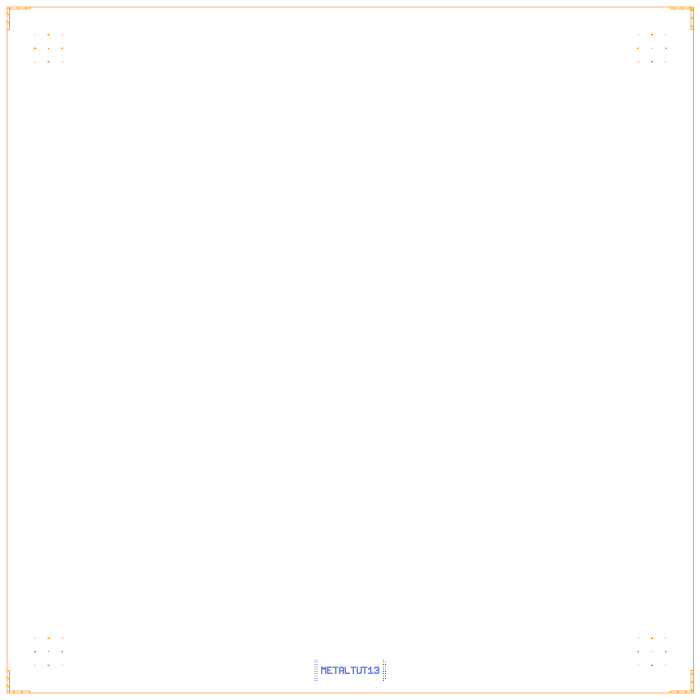

**On the chip so far:** 0 pads · 0 qubits · 0 other components · 0 routes · 0 declared couplings. **This step added** nothing new to the layout.

WindowsPath('examples/designs/metal/tut13_four_qubit_ring_s1_die.png')

In [5]:
d = Designer("tut13_four_qubit_ring", box=(750, -750, 8250, 6750), chip={"name_chip": "MetalTut13"}, live=LIVE)
layout_step(d, OUT / "tut13_four_qubit_ring_s1_die.png", size=(700, 700), width=350)

## Design 2 · Bond pads

Tutorial 1.3 has no launchpads (they come in tutorial 2.21 / example 51), so the PDK pad rule (outer etch edge 100 µm
from the die edge) has nothing to place here; `pads_md(d)` in Design 8 confirms there are none.

## Design 3 · Readout: the line

No feedline or readout pads either: the core has no readout.

## Design 4 · Qubit placement: four pocket transmons

**The qubits.** `metal:TransmonPocket` is Metal's pocket transmon drawn by the wrapper with the tutorial's options:
two 425 µm pads in a 650 µm-high pocket and four connection pads `a`–`d` at the corners (pad `b` 30 µm and `d`
50 µm high, pad `c` 200 µm wide: the tutorial varies them on purpose). Q2 / Q4 are rotated 90°.

**The junction.** With `junction_type` unset the wrapper already draws the Quantcore trilayer junction;
`trilayer_junction` makes it explicit and returns the drawn junction's L_J and C_J for the LOM and the FEM junction
port (`junction=`). The source's `FakeJunction_01` states no value, so every qubit gets the PDK nominal junction
(fingers 0.5 × 0.6 µm on 2/0 + 4/0, a 50/0 spacer with the 51–53/0 dose gradient, R_n 45 kΩ, L_J 6.73 nH,
C_J 15 fF).

Each component has named **ports** (Metal's pins): routes connect to them, and the LOM maps each to a circuit node.
The picture is the ring area, Metal's (±3.1, ±1.5) mm.

junction: {'junction_type': 'Quantcore Junction'} {'Lj_nH': 6.7344, 'Cj_fF': 15.0}


Q1 ports: ['a', 'b', 'c', 'd', 'squid_a', 'squid_b']


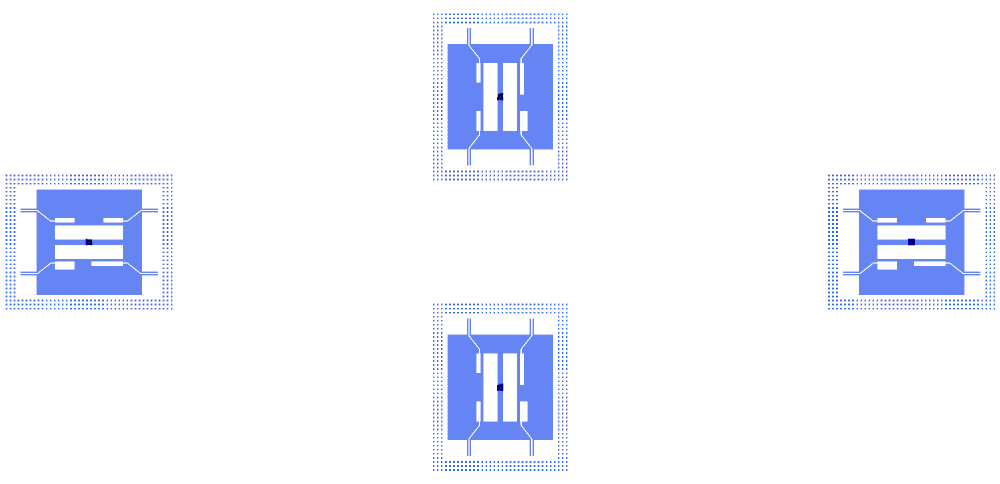

**On the chip so far:** 0 pads · 4 qubits · 0 other components · 0 routes · 0 declared couplings. **This step added** 4 component(s) `Q1`, `Q2`, `Q3`, `Q4`.

WindowsPath('examples/designs/metal/tut13_four_qubit_ring_step_parts.png')

In [6]:
# Quantcore trilayer junction on the PDK rule (Nb Δ 1.4 meV): nominal fingers 0.5 × 0.6 µm → R_n 45 kΩ,
# L_J 6.73 nH, C_J 15 fF. JJ_PARAMS = {"junction_type": "Quantcore Junction"}; JUNCTION = its {Lj_nH, Cj_fF}
JJ_PARAMS, JUNCTION = trilayer_junction("metal:TransmonPocket")
print("junction:", JJ_PARAMS, JUNCTION)
with d.batch():
    opts = dict(pad_width=425, pocket_height=650, junction=JUNCTION, **JJ_PARAMS,
                connection_pads={"a": {"loc_W": 1, "loc_H": 1}, "b": {"loc_W": -1, "loc_H": 1, "pad_height": 30},
                                 "c": {"loc_W": 1, "loc_H": -1, "pad_width": 200},
                                 "d": {"loc_W": -1, "loc_H": -1, "pad_height": 50}})
    q = {k: d.add(f"Q{k}", "metal:TransmonPocket", at=P(x, y), rot=r, **opts)
         for k, x, y, r in ((1, 2550, 0, 0), (2, 0, -900, 90), (3, -2550, 0, 0), (4, 0, 900, 90))}
print("Q1 ports:", sorted(q[1].ports))
layout_step(d, OUT / "tut13_four_qubit_ring_step_parts.png", box=P(-3100, -1500) + P(3100, 1500), size=(1000, 484),
            width=500)

## Design 5 · Readout: the resonators

None: the core has no readout resonators; the qubits' outward pads (`a` / `c` of Q1 / Q3, `b` / `d` of Q2 / Q4) stay
open, as in the source.

## Design 6 · Coupling: the ring of four λ/2 buses

Each bus runs from a Q1 / Q3 pad to a Q2 / Q4 pad. `meander=6000 + EPS` (or 6100) makes a fixed-length route whose
waypoints are Metal's own `RouteMeander` corner points (`bus()` in the setup cell): runs at 200 µm pitch alternating
between two distances from the axis, mirrored for each quadrant. The waypoint path is already Metal's length (to < 0.05 µm), so the
router draws no `Meander`: it puts the small leftover (the 0.05 µm and the rounding) into the free corners, whose bend radius
shrinks by a few nm. As λ/2 buses (open at both pads) they sit near 10.5 GHz.

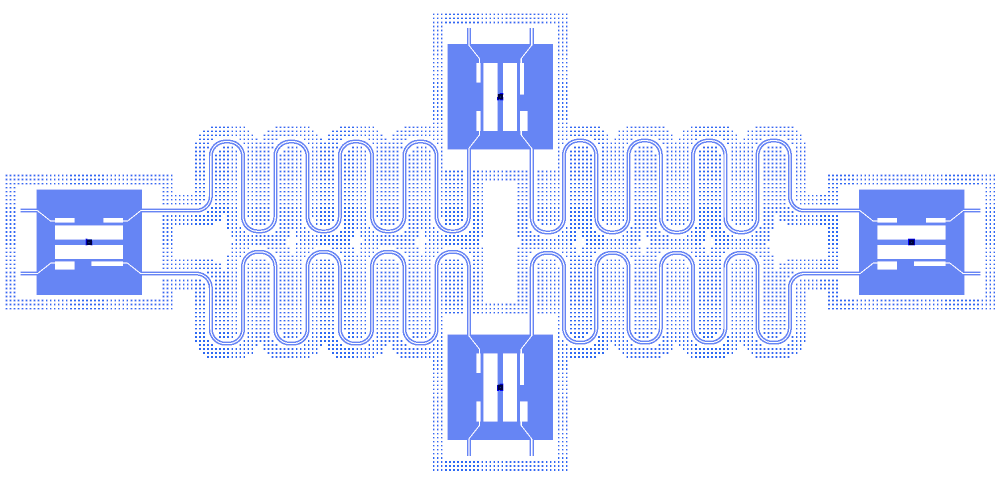

**On the chip so far:** 0 pads · 4 qubits · 0 other components · 4 routes · 0 declared couplings. **This step added** 4 route(s) `cpw1`, `cpw2`, `cpw3`, `cpw4`.

WindowsPath('examples/designs/metal/tut13_four_qubit_ring_s6_buses.png')

In [7]:
with d.batch():
    # buses: Metal's start / end pins and meander corners (runs 67.08 … 622.92 µm off the axis for 6.0 mm,
    # 60.83 … 629.17 µm for 6.1 mm)
    d.route("cpw1", q[1].d, q[2].c, meander=6000 + EPS, r=R, nodes=bus(622.92, 67.08, 1, -1))
    d.route("cpw2", q[3].c, q[2].a, meander=6100 + EPS, r=R, nodes=bus(629.17, 60.83, -1, -1))
    d.route("cpw3", q[3].a, q[4].b, meander=6000 + EPS, r=R, nodes=bus(622.92, 67.08, -1, 1))
    d.route("cpw4", q[1].b, q[4].d, meander=6100 + EPS, r=R, nodes=bus(629.17, 60.83, 1, 1))
layout_step(d, OUT / "tut13_four_qubit_ring_s6_buses.png", box=P(-3100, -1500) + P(3100, 1500), size=(1000, 484),
            width=500)

## Design 7 · Routing: control lines

None: the core has no charge or flux lines.

## Design 8 · The whole chip: sim groups, centring, save

**Sim groups:** the whole ring (nothing leaves the box) and Q1 alone (the box cuts its two buses once each), both
Q3D C-matrix jobs.

**Centring.** The PDK wants the chip content centred in the die. `center_in_die` measures the bounding box of everything placed
(components and routes) and shifts the design so its centre is the die centre. The die was placed on the source's
chip centre and the ring is symmetric, so nothing moves.

**Save.** The JSON is the deliverable. `save_design` writes it and compares it with the file it replaces (the
previous run's): the segments above changed how the chip is built, not the chip, so it should say *same design*.

content shifted by (0.0, 0.0) µm


| pad | cell / launcher | nearest die edge | outer etch → die edge (µm) | PDK rule |
|---|---|---|---|---|
| – | no bond pads or launchers | – | – | – |

**Same design as before:** `examples/designs/metal/tut13_four_qubit_ring.json` is identical to the file it replaces (byte for byte). The segments changed how the chip is built, not the chip.

<Designer tut13_four_qubit_ring: 4 instances, 4 routes, live=False> → examples\designs\metal\tut13_four_qubit_ring.json
{'cpw1': 6000.0, 'cpw2': 6100.0, 'cpw3': 6000.0, 'cpw4': 6100.0} (Metal 6000 / 6100 / 6000 / 6100 µm)


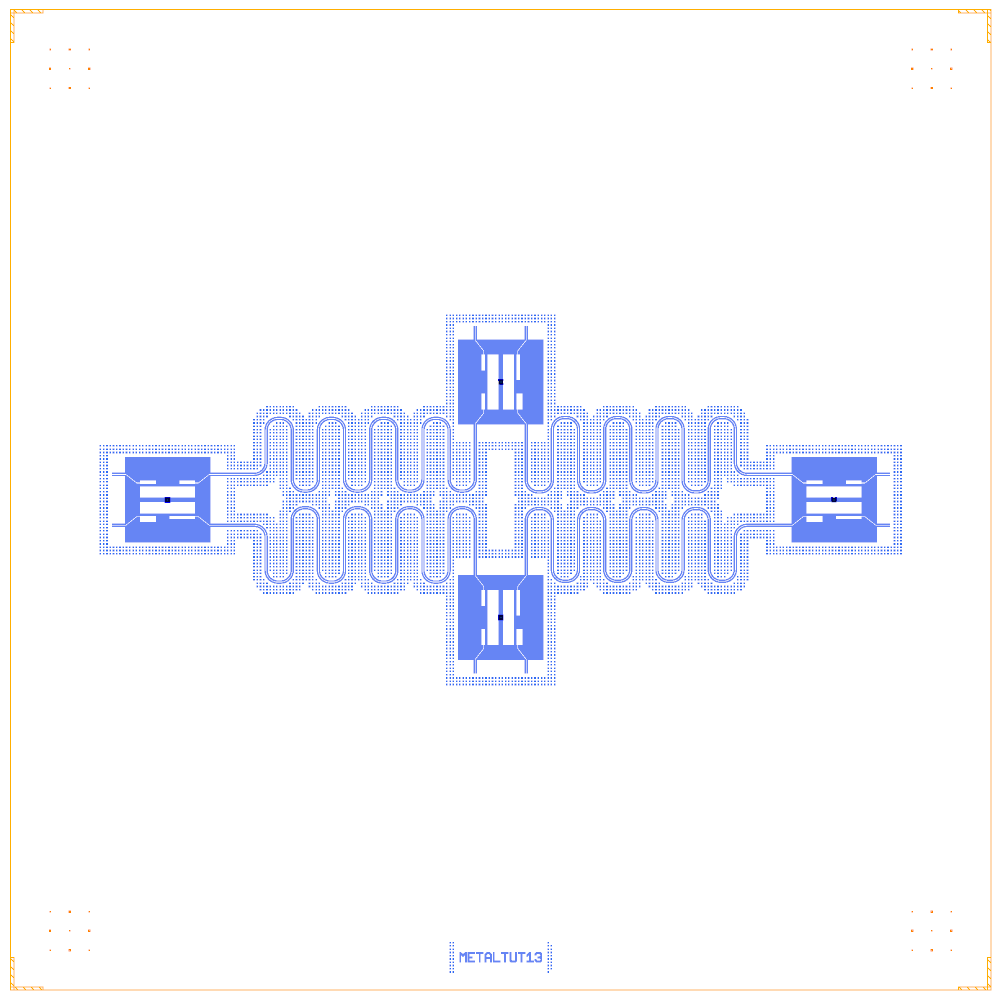

**On the chip so far:** 0 pads · 4 qubits · 0 other components · 4 routes · 0 declared couplings. **This step added** nothing new to the layout.

WindowsPath('examples/designs/metal/tut13_four_qubit_ring_step_routes.png')

In [8]:
# FEM boxes: the whole ring (nothing leaves it), and Q1 alone (the box cuts its two buses once each)
d.sim_group("ring", ["Q1", "Q2", "Q3", "Q4", "cpw1", "cpw2", "cpw3", "cpw4"], margin_um=150, analyses=["q3d_cmatrix"])
d.sim_group("Q1", ["Q1"], margin_um=50, analyses=["q3d_cmatrix"])
shift = center_in_die(d)
rebuild(d)
print("content shifted by", shift, "µm")
display(Markdown(pads_md(d)))
DESIGN, same = save_design(d, OUT / "tut13_four_qubit_ring.json")
display(Markdown(same))
print(d, "→", DESIGN)
print({k: round(v, 1) for k, v in d.result.route_lengths().items()}, "(Metal 6000 / 6100 / 6000 / 6100 µm)")
layout_step(d, OUT / "tut13_four_qubit_ring_step_routes.png", size=(1000, 1000), width=400)

# Check: DRC and netlist

The plugin's *Check* step: the design rules, then the lumped circuit the layout turns into.

## Check 1 · DRC

`d.drc()` checks connectivity (every port routed or snapped, route ends resolved), crossings, overlaps, the chip
box and the frame. It has three kinds of findings:
- **errors** (open, short, crossing, outside the chip): the design is broken; there must be none;
- **warnings** (an unused port, two component boxes overlapping): worth a look, often by design;
- **PDK design warnings** (`pad_edge`, `pdk_rn`, `pdk_fq`, `pdk_claw`): the design is valid but leaves a PDK
  margin. They are flagged, never fixed by retuning: the values are the source's.

Expected here (from the v1 run): **no errors**, sixteen `dangling_port` warnings: the eight junction attachment points
(`Q<k>.squid_a` / `squid_b`: the qubit cell draws the junction itself) and the eight outward pads (Q1 / Q3 `a`, `c`;
Q2 / Q4 `b`, `d`), which have no line, as in the source; and **no PDK design warnings** (no pads, the nominal
junction is in the R_n window, no targets).

`pdk_report(d)` sums up the PDK side: the cheese source, how far the content centre is from the die centre, the
junction types and the design warnings.

In [ ]:
rep = d.drc()
display(Markdown(drc_md(rep)))
display(Markdown(pdk_report(d)))

## Check 2 · Netlist

`d.lom()` turns the layout into a lumped circuit: each `TransmonPocket` gives two floating pad nodes with the
junction between them and a node per connection pad (the four outward pads couple to the pads but carry nothing, as
in the source); each bus between two pads is a λ/2 `TLres` (6.0 mm ≈ 10.67 GHz, 6.1 mm ≈ 10.49 GHz bare). The port
map shows which node each of Q1's ports landed on.

In [ ]:
lb = d.lom()
show_netlist(lb)
print({k: v for k, v in lb.port_map.items() if k.startswith("Q1.")})

# LOM: simulate the lumped circuit, and plot it

## LOM 1 · The LOM simulation

QuCat solves each sub-circuit's normal modes; QuTiP diagonalises the dressed Hamiltonian for f_q and α and the static
ZZ of each qubit pair. Each bus is simulated with the two qubits it joins.

With the PDK junction (6.73 nH, 15 fF; numbers from the v1 run) the qubits sit near 7.05 GHz linear (6.8 GHz dressed), ≈ 2.3 GHz below the
λ/2 buses (dispersive).
They share the junction but not their pads (pad `b` 30 µm and `d` 50 µm high, `c` 200 µm wide), so the pads each bus
lands on load the two qubits differently: a pair whose qubits come out within a few MHz hybridises through its bus
(ZZ "hybridised", not defined). The tutorial states no targets.

In [ ]:
ring = {"Q1+cpw1+Q2": ["Q1", "cpw1", "Q2"], "Q3+cpw2+Q2": ["Q3", "cpw2", "Q2"],
        "Q3+cpw3+Q4": ["Q3", "cpw3", "Q4"], "Q1+cpw4+Q4": ["Q1", "cpw4", "Q4"]}
coupled = simulate_groups(d, ring, max_modes=3)
for g, res in coupled.items():
    display(Markdown(f"**{g}, QuCat normal modes:**\n\n" + modes_md(res)))
display(Markdown("**Static ZZ (QuTiP):**\n\n" + zz_md(coupled)))

## LOM 2 · The LOM in two plots

The same results as pictures: (a) every normal mode of each bus group (QuCat; circles are qubits, squares the bus;
filled markers are the QuTiP dressed values), (b) the dispersive shift |χ| of each bus. Here (from the v1 run) the
four qubits sit within ≈ 50 MHz of each other, ≈ 2.3 GHz below the buses; in `Q3+cpw3+Q4` the two qubit modes are
mixed half and half (the hybridised pair of the ZZ table).

In [ ]:
plot_lom(coupled, OUT / "tut13_four_qubit_ring_lom.png", title="tut13: LOM per bus group")

## LOM 3 · One geometry change, by hand

Before the FEM, a hand-made design step: copy the saved design (`design_copy`: a non-live Designer that never writes over the
JSON), change one property — here Q1's `pad_width`, 425 → 450 µm (the value of the tutorial's own later variant) —
rebuild, re-run the LOM of Q1–cpw1–Q2 and compare. Wider pads add to Q1's C_Σ: Q1 moves down (≈ 90 MHz, past Q2), |α|
shrinks, and the Q1–Q2 detuning that sets the static ZZ changes.

In [ ]:
d2 = design_copy(DESIGN)
d2["Q1"].set(pad_width=450)                      # 425 → 450 µm
group = {"Q1+cpw1+Q2": ring["Q1+cpw1+Q2"]}
after = simulate_groups(d2, group, max_modes=3)
display(Markdown(params_delta_md({"Q1+cpw1+Q2": coupled["Q1+cpw1+Q2"]}, after)))

> **Simulation PC (32 GB+ RAM).** The cells below solve FEM jobs in AEDT. On this notebook's chip they need the
> simulation PC: set `RUN_FEM = True` and `FEM_FAST = False` there, run them one job at a time, and keep the results
> (`fem/`). On a smaller PC leave `RUN_FEM = False`: the cells export the jobs and load kept results only.

# Simulate: export to HFSS, the component and eigenmode simulations, the full-wave run

The plugin's *Simulate* step. The LOM above uses analytic capacitance estimates; a finite-element job measures them.
Each job is a sim group cut out of the chip, written to `build/jobs/<design>_<group>_<analysis>/`. With
`RUN_FEM = False` (the default) the jobs are only exported: the cells load results that were solved and kept before
(in `examples/designs/metal/fem/<job>/`), and otherwise say what would appear.

## Simulate 1 · Export to HFSS

The LOM uses analytic capacitance estimates; a finite-element job measures them. `export_sims` cuts each sim group
out of the chip (the box set by `sim_group`), puts ports where lines leave the box and writes a job folder under
`build/jobs/`. Simulation exports never get cheese, and airbridges are dropped unless asked for.

Q3D C-matrix jobs for both sim groups: `ring` (the four qubits with their buses: the island, pad and bus
capacitances and the pad-to-pad couplings) and `Q1` (Q1 alone: its C_Σ and pad capacitances, the box cutting its two
buses).

`FEM_FAST` (the switch at the top) picks the fast test settings for every job exported from here on. With
`RUN_FEM = True` the next cells solve each Ansys job in a **new batch, non-graphical** AEDT 2024 R1 (or newer), so an
AEDT window you have open is never touched. The command-line equivalent is `qcc hfss solve build/jobs/<job>`.

Neither group lists an eigenmode analysis, but `export_sims` exports any analysis of an existing group, so the
eigenmode job of `Q1` (Simulate 3) comes from the same design: nothing is added to it.

In [ ]:
FEM_FAST = fem_fast(FEM_FAST)                    # the switch from the top: fast test settings, or as written
KEEP = fem_keep_dir(DESIGN)                      # examples/designs/metal/fem/: solved results are kept here
jobs = export_sims(DESIGN)                       # Q3D C-matrix: one job per sim group
jobs_eig = export_sims(DESIGN, ["Q1"], analysis="eigenmode_epr")
display(Markdown(jobs_md(jobs) + "\n" + jobs_md(jobs_eig).split("\n", 2)[2]))

## Simulate 2 · Component simulation: the Q3D C-matrices

The capacitance of each component group: `ring` (the four qubits with the four buses: the island, pad and bus
capacitances and the pad-to-pad couplings) and `Q1` (Q1 alone: its C_Σ and pad capacitances, the box cutting its two
buses). Each net is named after its LOM node, so the matrix goes straight into the circuit (Results 3). `fem_stage`
solves each job with `RUN_FEM`, else loads its kept results, else says that there are none.

In [ ]:
keep_q3d = fem_stage(jobs, RUN_FEM, KEEP, force=RESOLVE, aedt=AEDT_MODE)
display(Markdown(convergence_md({f"{g} · q3d": k for g, k in keep_q3d.items()})))
for g, k in keep_q3d.items():
    if k:
        display(Markdown(cmatrix_md(k)))

## Simulate 3 · Eigenmode simulation

The `Q1` box in HFSS eigenmode: Q1's junction is a lumped L_J ‖ C_J sheet and the two buses the box cuts end in 50 Ω
there, so the qubit mode's Q is that loading (not a T1 of the chip, whose buses are open). pyEPR (run inside qcc's
own AEDT, never KQC's `run_pyepr_t1_estimate.py`) turns the junction's energy participation into Q1's dressed f_q and
α, to compare with the LOM.

In [ ]:
keep_eig = fem_stage(jobs_eig, RUN_FEM, KEEP, force=RESOLVE, aedt=AEDT_MODE)
display(Markdown(convergence_md({f"{g} · eigenmode": k for g, k in keep_eig.items()})))

## Simulate 4 · Full-wave (driven) run

Nothing to drive: the core has no readout resonator and no port of its own (an S21 between two cut bus ends would
not be a measurement of this chip).

# Results: plot, read the values, compare with the LOM, feed back, iterate

The plugin's *Results* step: what the FEM found, against the LOM and against a target, and the design change that
moves the chip towards the target.

## Results 1 · Plot the eigenmodes

(a) each mode's frequency over the adaptive passes (how the mesh converged), (b) the final modes, frequency against
Q, coloured by the junction participation p_J (≈ 1: the qubit), with the LOM's Q1 frequency as a dashed line. The
table below lists the modes and the pyEPR values.

In [ ]:
lom_f = {"Q1": coupled["Q1+cpw1+Q2"].params.get("Q1.f_q_GHz")}
plot_eigenmodes(keep_eig, OUT / "tut13_four_qubit_ring_eigenmodes.png", lom=lom_f)
for g, k in keep_eig.items():
    if k:
        display(Markdown(eigen_md(k)))

## Results 2 · The values

The eigenmode job in the LOM's terms: Q1's mode is the one its junction participates in most; f_q is pyEPR's dressed
frequency, α its self-Kerr. There is no readout to read (`epr_values` gets a placeholder readout, and only Q1's
values are kept).

In [ ]:
fem_q1 = {}
if keep_eig["Q1"]:
    fem_q1 = {k: v for k, v in epr_values(keep_eig["Q1"], {"Q1": "none"}, {"none": 0.0}).items() if k.startswith("Q1.")}
if fem_q1:
    display(Markdown("| quantity | FEM |\n|---|---|\n" + "\n".join(f"| `{k}` | {v:.5g} |" for k, v in fem_q1.items())))
else:
    print("No eigenmode results yet (RUN_FEM = True): this table would list Q1's f_q and α from pyEPR.")

## Results 3 · FEM against the LOM

**LOM on the Q3D C-matrix:** `fill` replaces the capacitance estimates of each bus group (LOM 1) by the `ring`
job's C-matrix values (matched by net name) and the same LOM runs again: f_q and α of every qubit. **FEM directly:**
Q1's eigenmode values (Results 2). The left column is the LOM on the component estimates (LOM 1).

In [ ]:
from quantcore_circuits.circuit.fill import fill

rows = []
if keep_q3d.get("ring"):
    for g, sel in ring.items():
        on_fem = simulate(fill(d.lom(select=sel).model, DESIGN, keep_q3d["ring"]), max_modes=3).params
        rows += [(f"{g}: {k}", v, on_fem.get(k), "LOM on the ring's Q3D C-matrix")
                 for k, v in coupled[g].params.items() if k.endswith(("f_q_GHz", "alpha_MHz"))]
est = coupled["Q1+cpw1+Q2"].params
rows += [(k, est.get(k), fem_q1[k], "Q1 eigenmode + pyEPR") for k in ("Q1.f_q_GHz", "Q1.alpha_MHz") if k in fem_q1]
if rows:
    display(Markdown(fem_vs_lom_md(rows)))
else:
    print("No FEM results yet: with RUN_FEM = True this table puts f_q and α of the LOM next to the LOM on the ring's "
          "Q3D C-matrix and next to Q1's eigenmode, with the difference in %.")

## Results 4 · Feedback: one step towards a target

The tutorial states no targets; in the LOM, Q3 and Q4 come out within a few MHz of each other and hybridise through
their bus (LOM 1). This notebook sets one target as an exercise that separates them: **Q4 at 6.65 GHz** (dressed),
≈ 0.15 GHz below where the LOM puts the qubits (from the v1 run: 6.77–6.81 GHz). It is reachable inside the PDK
junction window: by the transmon formula Q4's L_J goes from 6.73 nH to ≈ 7.0 nH, R_n ≈ 47 kΩ.

`loop.feedback` tunes qubit–readout pairs, and this chip has none: each bus is reached by two qubits, so the circuit
analysis treats it as a bus, not a readout. So the step is a first-order rule in the notebook: for a transmon
f_q ∝ 1/√L_J, so **L_J ← L_J · (f_now / f_target)²**, kept inside the PDK window (`pdk_lj_bounds`: R_n 40–50 kΩ). The
new L_J is drawn (`trilayer_junction(..., lj_nH=...)` sizes the fingers and gives C_J) on a copy of the design
(`design_copy`), and Q4 is measured again in its group `Q3+cpw3+Q4` (the LOM 1 call). Only L_J moves, so the
capacitances do not: when the `ring` Q3D job is kept (Simulate 2) its C-matrix fills every revision's circuit (the
FEM point), otherwise the LOM estimates do. The table shows one step.

In [ ]:
from quantcore_circuits.circuit.fill import fill

Q_T, F_T, TOL = "Q4", 6.65, 0.020                # the exercise target: Q4 at 6.65 GHz ± 20 MHz (dressed)
G_T = ring["Q3+cpw3+Q4"]                          # the LOM 1 group that measures it
LO, HI = pdk_lj_bounds(DESIGN)[f"{Q_T}.junction.Lj_nH"]   # the PDK R_n window as L_J bounds (nH)
FEM0 = keep_q3d.get("ring")                       # a kept Q3D job of the ring: its C-matrix holds for every revision


def measure(dd):
    """Q4's dressed f_q (GHz) on design dd: the LOM of its group, filled with the kept ring job when there is one."""
    return simulate(fill(dd.lom(select=G_T).model, dd.design, FEM0), max_modes=3).params.get(f"{Q_T}.f_q_GHz")


def lj_step(dd, f_now):
    """The feedback rule on dd: f_q ∝ 1/√L_J to first order, so L_J ← L_J · (f_now / F_T)², inside the PDK window;
    the new junction is drawn. Returns (L_J before, L_J drawn, whether the window clipped it)."""
    lj_now = dd.data["instances"][Q_T]["junction"]["Lj_nH"]
    want = lj_now * (f_now / F_T) ** 2
    jp, jj = trilayer_junction("metal:TransmonPocket", lj_nH=min(max(want, LO), HI))
    dd[Q_T].set(junction=jj, **jp)
    return lj_now, jj["Lj_nH"], not LO <= want <= HI


d_t = design_copy(DESIGN, "_target")             # the revisions are made on this copy; the design file stays
f0 = measure(d_t)
lj0, lj1, clipped = lj_step(d_t, f0)
f1 = measure(d_t)
display(Markdown(before_after_md({"Q4 L_J (nH)": lj0, "Q4 f_q (GHz)": f0}, {"Q4 L_J (nH)": lj1, "Q4 f_q (GHz)": f1})))
print(f"target {F_T} ± {TOL} GHz; one step leaves {1e3 * (f1 - F_T):+.1f} MHz" + (" (L_J at the PDK window's edge)" if clipped else ""))

## Results 5 · Iterate to the target

The feedback step, repeated on a fresh copy: measure → on target (± 20 MHz)? → else the rule again, until on target
or `MAX_ITER` steps. The rule is first order (f_q = √(8 E_J E_C) − E_C, not ∝ 1/√L_J), so a step falls a little short
and the next ones close the gap. The last revision is saved (`build/tut13_four_qubit_ring_target/`) and DRC-checked.
The table shows each iteration (on: FEM when the ring's C-matrix filled it, else LOM), the plot the residual in
tolerances (on target below 1).

In [ ]:
from quantcore_circuits.assembly.drc import check

d_t = design_copy(DESIGN, "_target")             # start again from the design
history, f = [], measure(d_t)
for k in range(MAX_ITER + 1):
    r = None if f is None else (f - F_T) / TOL
    history.append({"iteration": k, "design": Path(DESIGN.name if k == 0 else f"rev{k}"), "fem": FEM0 is not None,
                    "objective": None if r is None else abs(r), "values": {f"{Q_T}.f_q_GHz": f},
                    "targets": {f"{Q_T}.f_q_GHz": (F_T, TOL)}, "on_target": r is not None and abs(r) <= 1,
                    "knobs": {}, "notes": []})
    if history[-1]["on_target"] or r is None or k == MAX_ITER:
        break
    a, b, clipped = lj_step(d_t, f)
    history[-1]["knobs"] = {f"{Q_T}.junction.Lj_nH": (a, b)}
    if clipped:
        history[-1]["notes"].append("L_J at the edge of the PDK window")
    f = measure(d_t)
display(Markdown(history_md(history)))
plot_iterations(history, OUT / "tut13_four_qubit_ring_iterate.png")
rev = d_t.save(Path("build") / "tut13_four_qubit_ring_target" / f"rev{history[-1]['iteration']}.json")
print("last design:", rev, "· DRC:", "clean" if check(str(rev)).ok else "ERRORS", "· on target:", history[-1]["on_target"])

# Fab: the mask, snapshots, summary

## Fab 1 · Build and export

The design JSON saved in Design 8 is the deliverable: `qcc build`, `qcc mask` and the KLayout plugin all read it.
The fab export writes only the PDK fab layers (1/0 etch, 3/0 keep-out, 2/0 + 4/0 junction fingers, 50–53/0 spacer,
100/0 chip boundary, 1000/0 + 1001/0 frame markers), with corner rounding and the cheese.

**Cheese.** Tutorial 1.3 never exports a GDS, so the original has no cheese: the PDK band applies
(`cheese: "auto"`, the default). The build draws it into KQC's `ground_grid` layer (5 µm squares, 20 µm gaps, three
rows round the 3/0 keep-outs) and `export_fab` keeps it (`cheese source: build`).

Command-line equivalents:
- `qcc build examples/designs/metal/<id>.json` (the layout and its KLayout sidecar);
- `qcc mask examples/designs/metal/<id>.json` (the fab file; `--no-cheese`, `--no-round`);
- `qcc sim build examples/designs/metal/<id>.json -g <group> -a q3d_cmatrix` (one FEM job).

In [ ]:
print("design file:", DESIGN)
CHEESE = True
display(Markdown(fab_layers_md(d, cheese=CHEESE, rounding=True)))

## Fab 2 · Snapshots

The full chip (compare the tutorial's screenshot after the buses are added); Q1 with its four pads; its trilayer
junction; the cpw1 meander; the **fab mask** round Q1 (1/0 etch with the PDK cheese band, the 3/0 keep-out, the
junction layers); and the die frame's south-west corner (dicing L on 1000/0, alignment grid on 1001/0). Positions are
read from the design.

In [ ]:
qx, qy = d.data["instances"]["Q1"]["place"]["at"]
show_snapshot(d, OUT / "tut13_four_qubit_ring.png", size=(1400, 1400))
show_snapshot(d, OUT / "tut13_four_qubit_ring_q1.png", box=(qx - 450, qy - 400, qx + 450, qy + 400), width=420)
show_snapshot(d, OUT / "tut13_four_qubit_ring_jj.png", box=(qx - 40, qy - 40, qx + 40, qy + 40), width=300)
show_snapshot(d, OUT / "tut13_four_qubit_ring_bus.png", box=(qx - 2450, qy - 900, qx - 150, qy), size=(1600, 630),
              width=640)
snap_file(Path("build") / "tut13_four_qubit_ring_fab.oas", OUT / "tut13_four_qubit_ring_cheese.png",
          box=(qx - 450, qy - 400, qx + 450, qy + 400), size=(1350, 1200), width=420)
show_snapshot(d, OUT / "tut13_four_qubit_ring_frame.png", box=(750, -750, 1650, 150), size=(900, 900), width=300);

## Summary

| | |
|---|---|
| matches the source | every Metal component and option, positions and orientations, the bus end pins, Metal's meander corner points and lengths (6000 / 6100 / 6000 / 6100 µm), the sim groups |
| PDK changes | the 7.5 mm Quantcore die with the QCT frame (on the source's chip centre); sapphire stack; trilayer junctions (PDK nominal); PDK cheese band; content centred (no shift needed); no pads to place |
| differs | f_q with the PDK junction instead of the pre-rebuild 10 nH assumption (6.34–6.39 GHz) |
| LOM (from the v1 run) | f_q 6.77–6.81 GHz dressed (QuCat 7.03–7.08 linear), α −276…−284 MHz; buses 9.28–9.49 GHz dressed; χ(cpw1) −3.7 MHz; static ZZ Q1–Q2 438 kHz, Q2–Q3 545 kHz, Q1–Q4 275 kHz, Q3–Q4 hybridised |
| PDK design warnings | none |
| layout | built in segments (die, the four qubits, the ring buses, the whole chip; no pads, readouts or control lines); the saved JSON is the v1 notebook's |
| feedback | an exercise target (Q4 6.65 GHz, separating the hybridised Q3–Q4 pair) by a first-order L_J rule on a design copy (no qubit–readout pair for `loop.feedback`); LOM, or FEM capacitances when the ring's Q3D job is kept |
| open | the FEM jobs (Q3D, Q1 eigenmode) are exported, not solved (`RUN_FEM = False`): run with `RUN_FEM = True` to fill the Simulate and Results cells |